# Data overview

The training set has 12,260 images and the test set has 18,673. We predict five binary labels. Some images have no label, and some have more than one. Cat and Dog are common, while Moris, Motya, and Biatrix are very rare.

In [1]:
import pandas as pd
from pathlib import Path

root = Path.cwd()
if not (root / "data/train.csv").exists():
    root = root.parent

train = pd.read_csv(root / "data/train.csv")
test = pd.read_csv(root / "data/test.csv")

print("Train:", train.shape)
print("Test:", test.shape)

display(train.head())

Train: (12260, 6)
Test: (18673, 1)


,image_id,Cat,Dog,Moris,Motya,Biatrix
0,7e17a6e589f9c891857b32bbb3652d19b7d5a215,0,0,0,0,0
1,7ad97bd6c7ef98373f43f2bbd1e41b2bbff4687e,1,0,0,0,0
2,d29be872d012d8766c5942847d1d721788fd9511,0,1,0,0,0
3,bec7727bfc721629997d782ec020ee555990128f,0,1,0,0,0
4,58bb7362153d945f48721004bc8fb2ee73a855b0,0,1,0,0,0


In [2]:
labels = ["Cat", "Dog", "Moris", "Motya", "Biatrix"]

counts = train[labels].sum()
percentages = counts / len(train) * 100

distribution = pd.DataFrame({
    "Count": counts,
    "Percent": percentages.round(2)
})

display(distribution)

print("Background:", (train[labels].sum(axis=1) == 0).sum())
print("Multiple labels:", (train[labels].sum(axis=1) > 1).sum())

,Count,Percent
Cat,5077,41.41
Dog,5025,40.99
Moris,56,0.46
Motya,42,0.34
Biatrix,41,0.33


Background: 2162
Multiple labels: 125


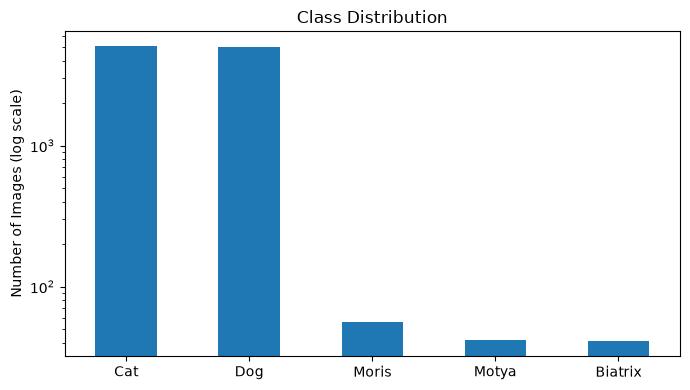

In [3]:
import matplotlib.pyplot as plt

counts.plot(kind="bar", figsize=(7, 4), logy=True)

plt.title("Class Distribution")
plt.ylabel("Number of Images (log scale)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

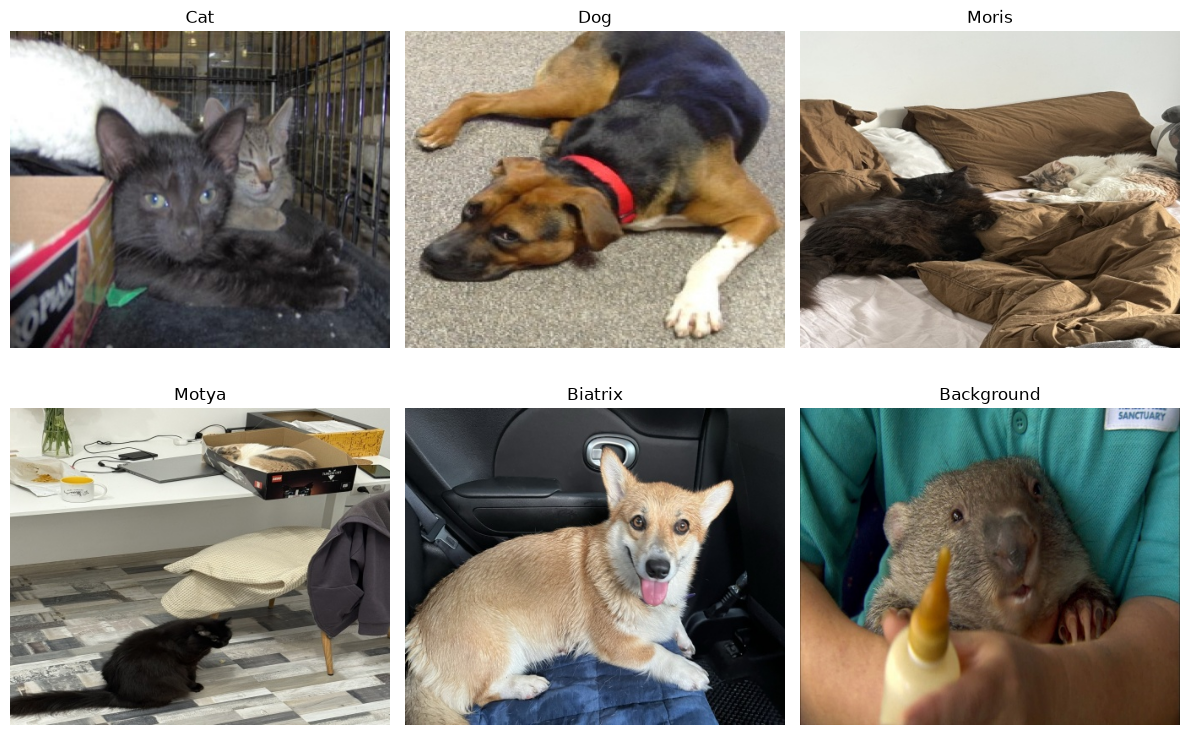

In [4]:
from PIL import Image

classes = labels + ["Background"]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, cls in zip(axes.flat, classes):
    if cls == "Background":
        subset = train[train[labels].sum(axis=1) == 0]
    else:
        subset = train[train[cls] == 1]

    row = subset.sample(1, random_state=42).iloc[0]
    path = root / "data/train" / f"{row['image_id']}.jpg"

    with Image.open(path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(cls)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [5]:
rows = []

for split, df in [("train", train), ("test", test)]:
    for image_id in df["image_id"].sample(200, random_state=42):
        path = root / "data" / split / f"{image_id}.jpg"

        with Image.open(path) as img:
            width, height = img.size
            rows.append((split, width, height, img.mode))

sizes = pd.DataFrame(rows, columns=["Split", "Width", "Height", "Mode"])

display(sizes.groupby("Split")[["Width", "Height"]].agg(["min", "median", "max"]))
print(sizes.groupby(["Split", "Mode"]).size())

Width             Height            
        min median  max    min median  max
Split                                     
test    450  450.0  450    375  375.0  375
train   450  450.0  450    375  375.0  375

Split  Mode
test   RGB     200
train  RGB     200
dtype: int64


## Metrics

Macro-F1 gives each of the five labels the same weight, which is useful because the rare classes matter. Its weakness is instability when a class has very few positive examples; it also depends on the prediction threshold. We use per-class precision and recall to see what errors the model makes. Macro Average Precision could be a useful threshold-independent alternative, but we do not calculate it here.

In [6]:
import numpy as np
from sklearn.metrics import f1_score

y_true = train[labels].values

# Simple example: always predict Cat and Dog
y_pred = np.zeros_like(y_true)
y_pred[:, 0] = 1
y_pred[:, 1] = 1

scores = f1_score(y_true, y_pred, average=None, zero_division=0)

print("Macro-F1:", round(scores.mean(), 4))
display(pd.Series(scores, index=labels, name="F1"))

Macro-F1: 0.2334


Cat        0.585684
Dog        0.581429
Moris      0.000000
Motya      0.000000
Biatrix    0.000000
Name: F1, dtype: float64

## Validation

We use 5-fold multilabel stratification (seed 42) to keep rare-label counts similar between folds. We also put exact duplicate files in the same fold to avoid direct leakage. We did not check near-duplicates. No time or group metadata is provided in the CSV files, so we cannot make a time-based or group-based split. The saved `folds.csv` is shared across the team.

In [7]:
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold

cv = MultilabelStratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train["fold"] = -1

for fold, (_, val_idx) in enumerate(cv.split(train, train[labels])):
    train.loc[val_idx, "fold"] = fold

print(train["fold"].value_counts().sort_index())
display(train.groupby("fold")[labels].sum())

fold
0    2452
1    2452
2    2452
3    2452
4    2452
Name: count, dtype: int64


,Cat,Dog,Moris,Motya,Biatrix
fold,,,,,
0,1015,1005,11,8,9
1,1016,1005,12,8,8
2,1015,1005,11,9,8
3,1016,1005,11,8,8
4,1015,1005,11,9,8


In [8]:
from collections import defaultdict
import hashlib

hashes = defaultdict(list)
hash_by_id = {}

for _, row in train.iterrows():
    path = root / "data/train" / f"{row['image_id']}.jpg"

    with open(path, "rb") as f:
        h = hashlib.sha256(f.read()).hexdigest()

    hashes[h].append(row["fold"])
    hash_by_id[row["image_id"]] = h

duplicates = [v for v in hashes.values() if len(v) > 1]
leakage = [v for v in duplicates if len(set(v)) > 1]

print("Duplicate groups:", len(duplicates))
print("Duplicates across folds:", len(leakage))

Duplicate groups: 5
Duplicates across folds: 3


In [9]:
df_hash = train[["image_id", "fold"] + labels].copy()
df_hash["hash"] = df_hash["image_id"].map(hash_by_id)

dup = df_hash[df_hash.duplicated("hash", keep=False)].copy()
dup["group"] = dup.groupby("hash").ngroup() + 1

display(dup.sort_values(["group", "fold"]).drop(columns="hash"))

,image_id,fold,Cat,Dog,Moris,Motya,Biatrix,group
149,3b07697e27a527755a4216bf8055a3b79b68f104,0,0,1,0,0,0,1
532,5614ff0793569336073aa6cb231a28848b55fc3c,3,0,1,0,0,0,1
7298,16dad32b1bfd8c4129a68cdf926374aa219861bf,0,1,0,0,0,0,2
7765,89d48c6c5391c5ff1ed6d76909a11ca80687641b,1,1,0,0,0,0,2
208,dc59ae12ac959ef428584eb4cc35876a2dfb5e77,2,1,0,0,0,0,3
10810,3fcf3dc4635a80f65b54ecd39df4aacec3356992,2,1,0,0,0,0,3
3950,3e0f768fb6189230a9e80c6ef97ea726c56f48cb,0,1,0,0,0,0,4
6207,fd53cc3b076b0a8057ba01a2603ae379c01e9e8d,0,1,0,0,0,0,4
12207,6456d87e01e810c86f96ad977e1e8d9df4591862,1,0,1,0,0,0,5
3432,1b51b41f6a312a1e620f19c95672bc1f53444fcd,3,0,1,0,0,0,5


In [10]:
for _, pair in dup.groupby("group"):
    i, j = pair.index

    fold1 = train.at[i, "fold"]
    fold2 = train.at[j, "fold"]

    if fold1 == fold2:
        continue

    same_labels = (train[labels] == train.loc[j, labels]).all(axis=1)

    candidates = train.index[
        (train["fold"] == fold1)
        & same_labels
        & ~train.index.isin(dup.index)
    ]

    swap = candidates[0]

    train.at[j, "fold"] = fold1
    train.at[swap, "fold"] = fold2

# Check the result
dup_folds = train.loc[dup.index, "fold"]

check = dup.assign(fold=dup_folds).groupby("group")["fold"].nunique()

print("Duplicates across folds:", (check > 1).sum())
print("\nFold sizes:")
print(train["fold"].value_counts().sort_index())

display(train.groupby("fold")[labels].sum())

Duplicates across folds: 0

Fold sizes:
fold
0    2452
1    2452
2    2452
3    2452
4    2452
Name: count, dtype: int64


,Cat,Dog,Moris,Motya,Biatrix
fold,,,,,
0,1015,1005,11,8,9
1,1016,1005,12,8,8
2,1015,1005,11,9,8
3,1016,1005,11,8,8
4,1015,1005,11,9,8


In [11]:
folds = train[["image_id", "fold"]]

folds.to_csv(root / "folds.csv", index=False)

print("Saved:", len(folds), "images")
display(folds.head())

Saved: 12260 images


,image_id,fold
0,7e17a6e589f9c891857b32bbb3652d19b7d5a215,4
1,7ad97bd6c7ef98373f43f2bbd1e41b2bbff4687e,1
2,d29be872d012d8766c5942847d1d721788fd9511,1
3,bec7727bfc721629997d782ec020ee555990128f,1
4,58bb7362153d945f48721004bc8fb2ee73a855b0,2


In [12]:
saved = pd.read_csv(root / "folds.csv")

assert len(saved) == len(train)
assert saved["image_id"].is_unique
assert set(saved["image_id"]) == set(train["image_id"])

pd.testing.assert_frame_equal(
    saved,
    train[["image_id", "fold"]],
    check_dtype=False
)

print("Folds saved correctly!")
print(saved["fold"].value_counts().sort_index())

Folds saved correctly!
fold
0    2452
1    2452
2    2452
3    2452
4    2452
Name: count, dtype: int64
